Break dates: ['2021-12-13', '2021-12-20', '2022-01-04', '2022-01-19']
Break indices: [12, 19, 34, 49]


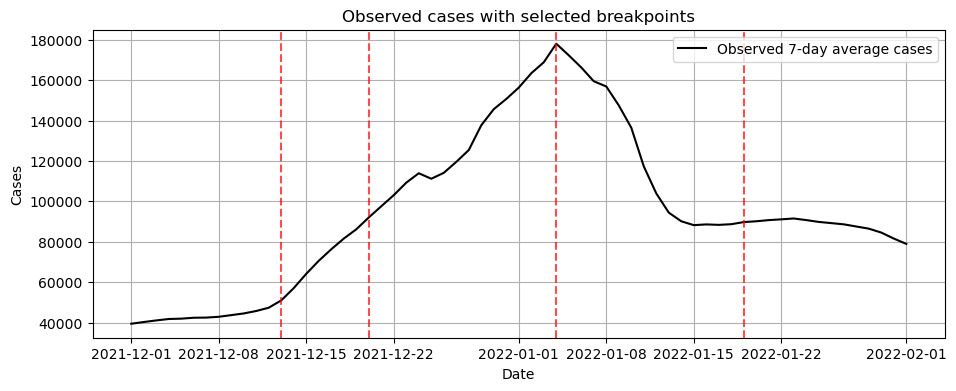

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import minimize

# load data
df = pd.read_csv("../data/uk_final.csv")
df["date"] = pd.to_datetime(df["date"])

# fitting window
df_fit = df[(df["date"] >= "2021-12-01") & (df["date"] <= "2022-02-01")].copy()
df_fit = df_fit.reset_index(drop=True)

data = df_fit["cases_7d"].values.astype(float)
dates = df_fit["date"].values
t_eval = np.arange(len(data), dtype=float)

# population
N = 67_000_000

# chosen breakpoints
break_dates = ["2021-12-13", "2021-12-20", "2022-01-04", "2022-01-19"]
break_indices = [int(np.where(df_fit["date"] == pd.Timestamp(d))[0][0]) for d in break_dates]

# fixed settings
tau_fixed = 4
gamma_fixed = 1 / 7

print("Break dates:", break_dates)
print("Break indices:", break_indices)

# quick check plot
plt.figure(figsize=(11, 4))
plt.plot(df_fit["date"], data, label="Observed 7-day average cases", color="black")
for d in break_dates:
    plt.axvline(pd.Timestamp(d), color="red", linestyle="--", alpha=0.7)
plt.title("Observed cases with selected breakpoints")
plt.xlabel("Date")
plt.ylabel("Cases")
plt.legend()
plt.grid()
plt.show()

In [2]:
def beta_piecewise_constant(tt, break_indices, beta_values):
    bounds = [0] + break_indices + [10**9]
    for k in range(len(beta_values)):
        if bounds[k] <= tt < bounds[k + 1]:
            return beta_values[k]
    return beta_values[-1]

def sir_rhs(t_now, y, break_indices, beta_values, gamma, N):
    S, I, R = y
    beta_t = beta_piecewise_constant(t_now, break_indices, beta_values)
    dSdt = -beta_t * S * I / N
    dIdt = beta_t * S * I / N - gamma * I
    dRdt = gamma * I
    return [dSdt, dIdt, dRdt]

def simulate_sir_piecewise_constant(break_indices, beta_values, gamma, S0, I0, R0, N, t_eval):
    sol = solve_ivp(
        fun=lambda t_now, y: sir_rhs(t_now, y, break_indices, beta_values, gamma, N),
        t_span=(t_eval[0], t_eval[-1]),
        y0=[S0, I0, R0],
        t_eval=t_eval,
        method="RK45",
        rtol=1e-8,
        atol=1e-10
    )

    if not sol.success:
        raise RuntimeError(sol.message)

    S = sol.y[0]
    I = sol.y[1]
    R = sol.y[2]
    beta_path = np.array([beta_piecewise_constant(tt, break_indices, beta_values) for tt in t_eval])
    incidence = beta_path * S * I / N
    return S, I, R, beta_path, incidence

def apply_fixed_delay(x, tau):
    tau = int(tau)
    y = np.empty_like(x)
    if tau <= 0:
        return x.copy()
    y[:tau] = x[0]
    y[tau:] = x[:-tau]
    return y

n_seg = len(break_indices) + 1   # 5 beta values

def loss_fn(params):
    beta_values = params[:n_seg]
    rho = params[n_seg]
    I0 = params[n_seg + 1]

    if np.any(np.array(beta_values) <= 0):
        return 1e20
    if rho <= 0 or I0 <= 0 or I0 >= N:
        return 1e20

    R0 = 0.0
    S0 = N - I0 - R0

    try:
        S_fit, I_fit, R_fit, beta_path, incidence = simulate_sir_piecewise_constant(
            break_indices, beta_values, gamma_fixed, S0, I0, R0, N, t_eval
        )
    except Exception:
        return 1e20

    delayed_incidence = apply_fixed_delay(incidence, tau_fixed)
    fitted_cases = rho * delayed_incidence

    if np.any(np.isnan(fitted_cases)) or np.any(np.isinf(fitted_cases)) or np.any(fitted_cases < 0):
        return 1e20

    eps = 1.0
    return np.mean((np.log(fitted_cases + eps) - np.log(data + eps)) ** 2)

# initial guess and bounds
x0 = [
    0.20, 0.22, 0.19, 0.12, 0.14,   # beta1 ... beta5
    1.0,                            # rho
    data[0] * 5.0                   # I0
]

bounds = (
    [(1e-6, 1.5)] * n_seg +
    [(1e-6, 100.0)] +
    [(1.0, 5_000_000.0)]
)

result = minimize(
    loss_fn,
    x0=x0,
    bounds=bounds,
    method="L-BFGS-B"
)

if not result.success:
    print("Optimization message:", result.message)

best_params = result.x
beta_values = best_params[:n_seg]
rho = best_params[n_seg]
I0 = best_params[n_seg + 1]

R0 = 0.0
S0 = N - I0 - R0

S_fit, I_fit, R_fit, beta_path, incidence = simulate_sir_piecewise_constant(
    break_indices, beta_values, gamma_fixed, S0, I0, R0, N, t_eval
)

delayed_incidence = apply_fixed_delay(incidence, tau_fixed)
fitted_cases = rho * delayed_incidence

mse = np.mean((fitted_cases - data) ** 2)
rmse = np.sqrt(mse)
log_mse = np.mean((np.log(fitted_cases + 1.0) - np.log(data + 1.0)) ** 2)

print("\nChosen model: bp_4_tau4_fixed_1_7")
print("Break dates:", break_dates)
print("tau_fixed   =", tau_fixed)
print("gamma_fixed =", gamma_fixed)
print("beta_values =", beta_values)
print("rho         =", rho)
print("I0          =", I0)
print("MSE         =", mse)
print("RMSE        =", rmse)
print("log_MSE     =", log_mse)


Chosen model: bp_4_tau4_fixed_1_7
Break dates: ['2021-12-13', '2021-12-20', '2022-01-04', '2022-01-19']
tau_fixed   = 4
gamma_fixed = 0.14285714285714285
beta_values = [0.19720956 0.21712576 0.18794278 0.11950334 0.14051139]
rho         = 0.998778319301839
I0          = 197113.57108295552
MSE         = 91990798.60434364
RMSE        = 9591.183378725675
log_MSE     = 0.008147354266345393



Summary table:
        quantity            value
0   breakpoint_1       2021-12-13
1   breakpoint_2       2021-12-20
2   breakpoint_3       2022-01-04
3   breakpoint_4       2022-01-19
4          beta1          0.19721
5          beta2         0.217126
6          beta3         0.187943
7          beta4         0.119503
8          beta5         0.140511
9            tau                4
10         gamma         0.142857
11           rho         0.998778
12            I0    197113.571083
13           MSE  91990798.604344
14          RMSE      9591.183379
15       log_MSE         0.008147


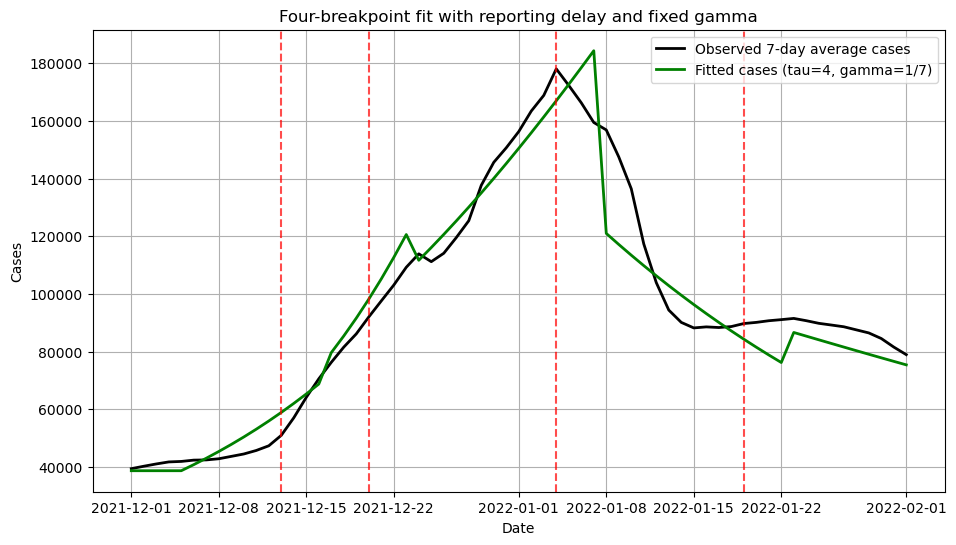

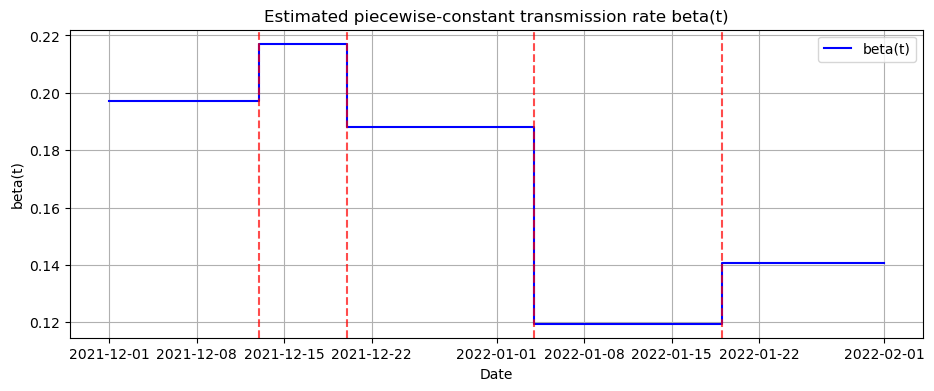

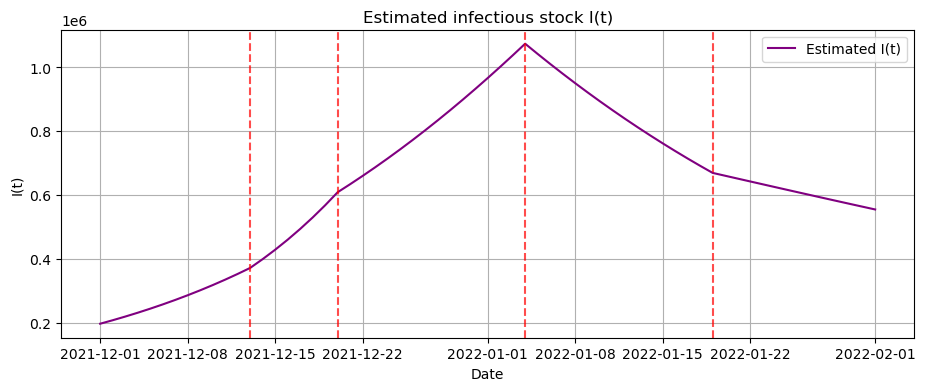

In [4]:
summary = pd.DataFrame({
    "quantity": [
        "breakpoint_1", "breakpoint_2", "breakpoint_3", "breakpoint_4",
        "beta1", "beta2", "beta3", "beta4", "beta5",
        "tau", "gamma", "rho", "I0",
        "MSE", "RMSE", "log_MSE"
    ],
    "value": [
        break_dates[0], break_dates[1], break_dates[2], break_dates[3],
        beta_values[0], beta_values[1], beta_values[2], beta_values[3], beta_values[4],
        tau_fixed, gamma_fixed, rho, I0,
        mse, rmse, log_mse
    ]
})

print("\nSummary table:")
print(summary)

summary.to_csv("../results/bp_4_tau4_fixed_1_7_summary.csv", index=False)

plt.figure(figsize=(11, 6))
plt.plot(df_fit["date"], data, label="Observed 7-day average cases", linewidth=2, color="black")
plt.plot(df_fit["date"], fitted_cases, label="Fitted cases (tau=4, gamma=1/7)", linewidth=2, color="green")
for d in break_dates:
    plt.axvline(pd.Timestamp(d), color="red", linestyle="--", alpha=0.7)
plt.title("Four-breakpoint fit with reporting delay and fixed gamma")
plt.xlabel("Date")
plt.ylabel("Cases")
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(11, 4))
plt.step(df_fit["date"], beta_path, where="post", label="beta(t)", color="blue")
for d in break_dates:
    plt.axvline(pd.Timestamp(d), color="red", linestyle="--", alpha=0.7)
plt.title("Estimated piecewise-constant transmission rate beta(t)")
plt.xlabel("Date")
plt.ylabel("beta(t)")
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(11, 4))
plt.plot(df_fit["date"], I_fit, color="purple", label="Estimated I(t)")
for d in break_dates:
    plt.axvline(pd.Timestamp(d), color="red", linestyle="--", alpha=0.7)
plt.title("Estimated infectious stock I(t)")
plt.xlabel("Date")
plt.ylabel("I(t)")
plt.legend()
plt.grid()
plt.show()